# Trend and Seasonality of the Intra-Day Arbitrage Spread in the ERCOT Day-Ahead Market

## BESS capacity is expanding rapidly in ERCOT.

## Hypothesis: installed BESS capacity decreases the intra-day spread. Here we decompose the spread into trend, weekly and yearly seasonality and compare the trend with installed capacity.

In [1]:
%matplotlib inline

In [ ]:
from datetime import date

import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats.mstats import winsorize
from statsforecast import StatsForecast
from statsforecast.models import MSTL

from modo_energy_client.modo_energy_api_client import ModoEnergyAPIClient

In [3]:
start = date(2022, 9, 11)
end = date(2026, 10, 23)
settlement_point_name = "HB_HOUSTON"

In [4]:
modo_client = ModoEnergyAPIClient(
    cache_requests=True,
)

#### Get battery energy data from Modo

#### Data is reported monthly by owner so we sum it to total installed energy capacity (GWh).


In [5]:
ercot_bess = modo_client.get_ercot_bess_owners(
    date_from=start,
    date_to=end,
)

ercot_bess["month"] = ercot_bess["date"].dt.to_period("M").dt.to_timestamp()
ercot_bess_capacity = (
    ercot_bess.groupby("month")
    .agg(bess_capacity_gwh=("total_energy_capacity_mwh", "sum"))
    .div(1000)
    .resample("D")
    .ffill()
)

Fetching pages: 0page [00:00, ?page/s]

#### Get day-ahead settle price point

#### Winsorize to remove outliers, some are data errors others are market anomalies.

#### Arbitrage is defined as buying at 12pm and selling at 7pm.


In [6]:
prices = modo_client.get_ercot_prices(date_from=start, date_to=end)

hub_prices = prices[prices["settlementPointName"] == settlement_point_name][
    "settlementPointPrice"
]

hub_prices_winsorized = pd.DataFrame(
    {hub_prices.name: winsorize(hub_prices, limits=[None, 0.01])},
    index=hub_prices.index,
)

arbitrage_spread = (
    hub_prices_winsorized.resample("D")
    .agg(lambda d: max(d[d.index.hour == 19].item() - d[d.index.hour == 12].item(), 0))
    .rename(columns={"settlementPointPrice": "arbitrage_spread"})
)

Fetching pages: 0page [00:00, ?page/s]

#### Decompose the spread

#### MSTL (multiple seasonal-trend decomposition using LOESS) splits the daily spread into a smooth trend, a weekly and a yearly seasonal component, and a remainder.

In [8]:
spread = (
    arbitrage_spread.reset_index()
    .rename(columns={"deliveryDate": "ds", "arbitrage_spread": "y"})
    .assign(unique_id="spread")
)

sf = StatsForecast(models=[MSTL(season_length=[7, 365])], freq="D")
sf.fit(spread)

decomposition = sf.fitted_[0, 0].model_.set_index(spread["ds"])
decomposition.head()

,data,trend,seasonal7,seasonal365,remainder
ds,,,,,
2022-09-11,65.03,31.654948,-7.522128,15.058673,25.838507
2022-09-12,65.27,31.749539,-1.036082,6.629233,27.927310
2022-09-13,30.88,31.844166,2.488375,-15.725052,12.272511
2022-09-14,28.31,31.938829,28.739197,-13.237716,-19.130310
2022-09-15,28.32,32.033528,17.165651,-3.144230,-17.734948


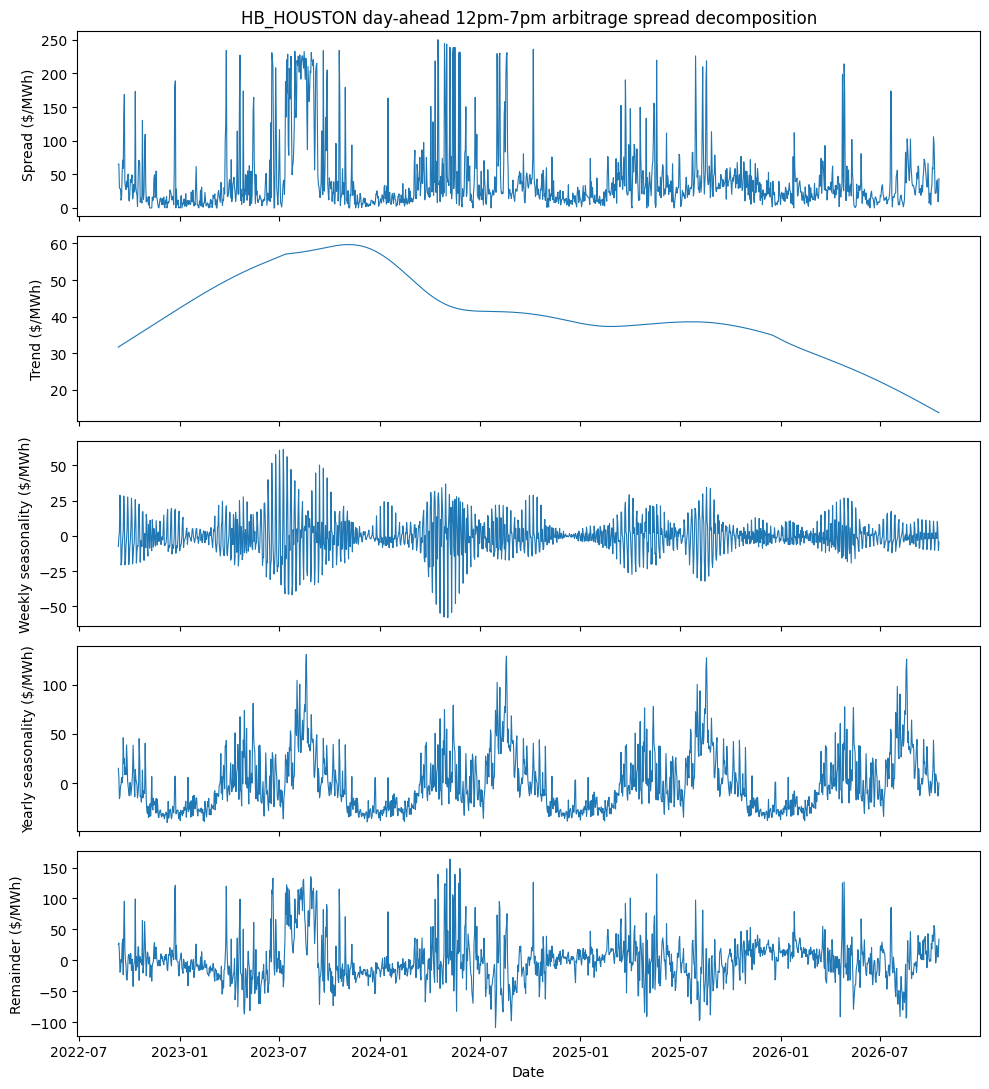

In [9]:
labels = {
    "data": "Spread ($/MWh)",
    "trend": "Trend ($/MWh)",
    "seasonal7": "Weekly seasonality ($/MWh)",
    "seasonal365": "Yearly seasonality ($/MWh)",
    "remainder": "Remainder ($/MWh)",
}
fig1, axes = plt.subplots(len(labels), 1, figsize=(10, 11), sharex=True)
for ax, (column, label) in zip(axes, labels.items()):
    ax.plot(decomposition.index, decomposition[column], linewidth=0.8)
    ax.set_ylabel(label)
axes[0].set_title(
    f"{settlement_point_name} day-ahead 12pm-7pm arbitrage spread decomposition"
)
axes[-1].set_xlabel("Date")
fig1.tight_layout()

#### Trend vs installed BESS capacity

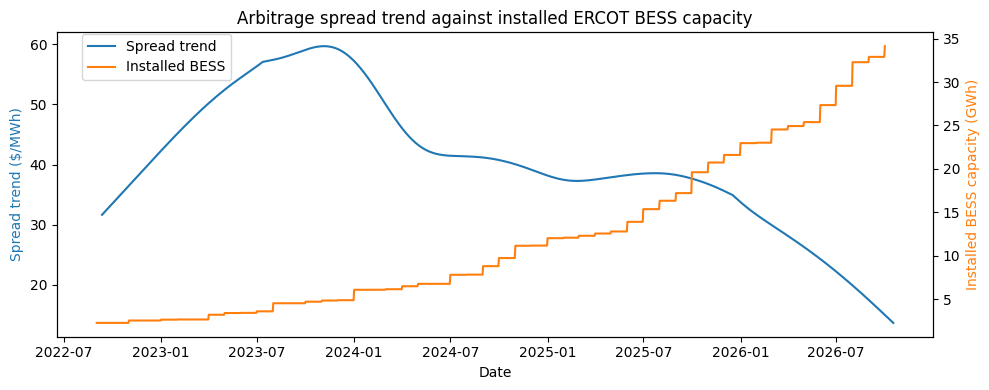

In [10]:
fig2, ax = plt.subplots(figsize=(10, 4))
ax.plot(decomposition.index, decomposition["trend"], color="C0", label="Spread trend")
ax.set_xlabel("Date")
ax.set_ylabel("Spread trend ($/MWh)", color="C0")

ax2 = ax.twinx()
ax2.plot(
    ercot_bess_capacity.index,
    ercot_bess_capacity["bess_capacity_gwh"],
    color="C1",
    label="Installed BESS",
)
ax2.set_ylabel("Installed BESS capacity (GWh)", color="C1")

ax.set_title("Arbitrage spread trend against installed ERCOT BESS capacity")
fig2.legend(loc="upper left", bbox_to_anchor=(0.08, 0.92))
fig2.tight_layout()